### Pré-processamento dos Dados de EEG

Este notebook aplica filtros temporais aos dados de EEG e realiza a comparação visual dos sinais antes e depois da filtragem.
Os filtros aplicados são:
1. **Filtro Notch (50 Hz)**
2. **Filtro Passa-Banda (Bandpass 1.0 – 30.0 Hz)**


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np

# Caminho do arquivo de epochs gerado na etapa de carregamento
DATA_DIR = Path("../../output") if Path("../../output").exists() else Path("./output")
fif_file = DATA_DIR / "eeg_epochs-epo.fif"

# Carregando os dados do arquivo .fif de epochs
epochs = mne.read_epochs(str(fif_file))
print("Epochs carregadas com sucesso:")
print(epochs)


Reading /home/andre/Documentos/Git/neural-ca/src/jupyter/../../output/eeg_epochs-epo.fif ...
Isotrak not found
    Found the data of interest:
        t =       0.00 ...    1998.05 ms
        0 CTF compensation matrices available
Not setting metadata
1151 matching events found
No baseline correction applied
0 projection items activated
Epochs carregadas com sucesso:
<EpochsFIF | 1151 events (all good), 0 – 1.998 s (baseline off), ~260.8 MiB, data loaded,
 'eeg': 1151>


---
### 1. Parâmetros e Seleção dos Canais para Visualização


In [2]:
# Dinamizando parâmetros
epo = 10  # Índice da época de exemplo para inspeção
channels_8 = ['EEG Fp1', 'EEG F3', 'EEG C3', 'EEG P3', 'EEG O1', 'EEG Fz', 'EEG Cz', 'EEG Pz']

# Selecionando apenas os 8 canais de interesse para o plot
epochs_8 = epochs.copy().pick(picks=channels_8)
print(f"Época selecionada: {epo}")
print(f"Canais selecionados para plot (8 canais): {epochs_8.ch_names}")


Época selecionada: 10
Canais selecionados para plot (8 canais): ['EEG Fp1', 'EEG F3', 'EEG C3', 'EEG P3', 'EEG O1', 'EEG Fz', 'EEG Cz', 'EEG Pz']


In [ ]:
def plots_evoked(evoked_data, color="red", title="Época Isolada - 8 Canais"):
    # Extrai dados (canais x tempos) e o vetor de tempo
    data = evoked_data.get_data()
    if data.ndim == 3:
        data = data[0]  # seleciona a primeira época para torná-lo 2D (canais x tempo)
    
    times = evoked_data.times
    ch_names = evoked_data.ch_names

    # Configura a grade de 8 blocos (4 linhas x 2 colunas)
    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 10), sharex=True)
    axes = axes.flatten()

    for i, channel_name in enumerate(ch_names):
        ax = axes[i]

        ax.plot(times, data[i], label=channel_name, color=color)
        ax.set_title(f"Canal: {channel_name}")
        ax.grid(True, linestyle="--", alpha=0.5)

        # Rótulo do eixo Y apenas na coluna da esquerda
        if i % 2 == 0:
            ax.set_ylabel("Amplitude (uV)")

        # Rótulo do eixo X apenas na última linha
        if i >= 6:
            ax.set_xlabel("Tempo (s)")

    # Ajusta o layout para evitar sobreposições
    plt.tight_layout()
    plt.suptitle(title, y=1.02, fontsize=14)
    plt.show()


---
### 3. Dados Brutos

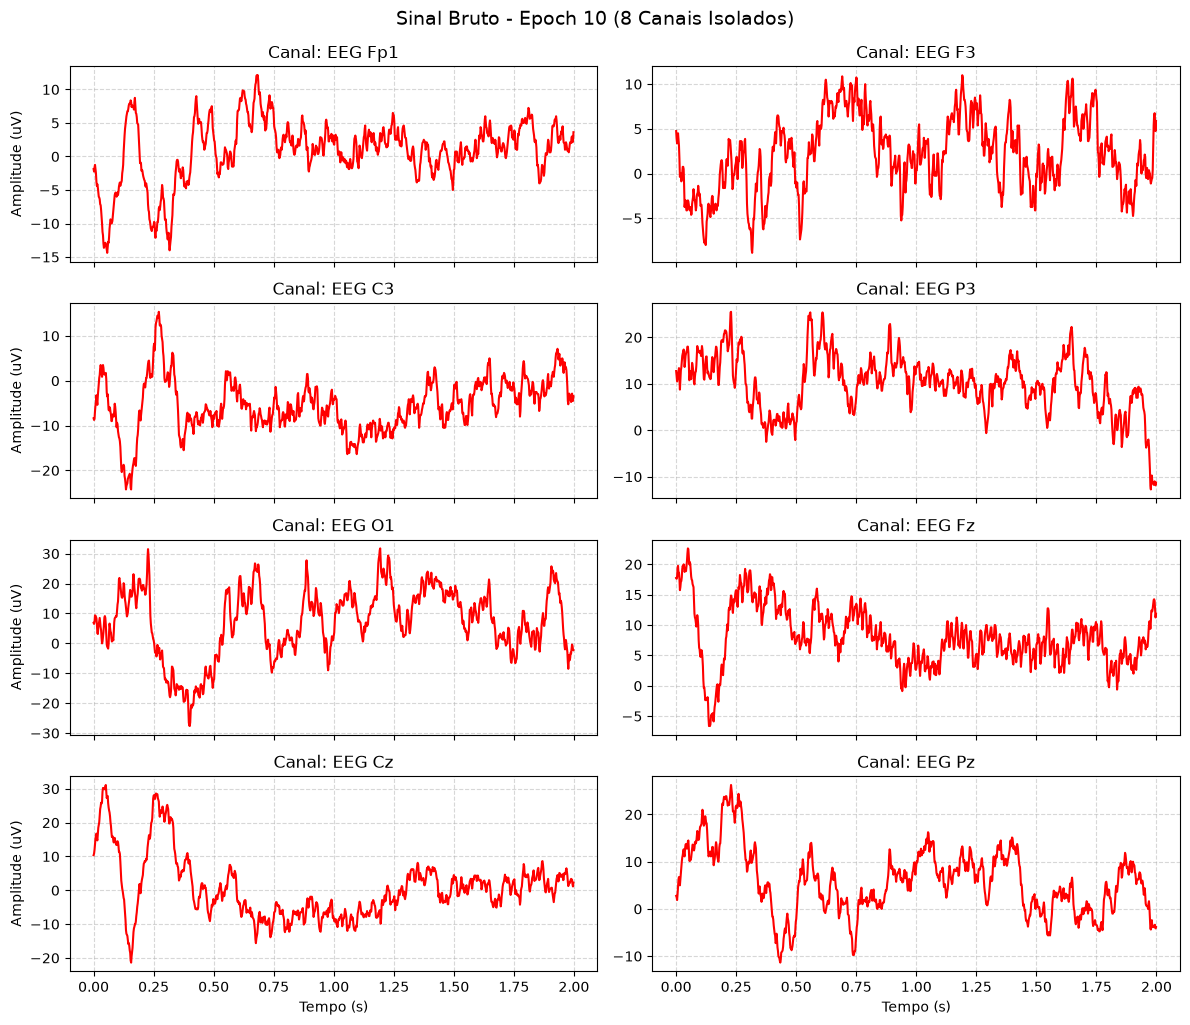

In [4]:
# Obtendo 1 época para o plot bruto
plots_evoked(epochs_8[epo], color="red", title=f"Sinal Bruto - Epoch {epo} (8 Canais Isolados)")


---
### 4. Aplicação dos Filtros Temporais (Notch e Passa-Banda)

1. **Filtro Notch (50 Hz)**:
2. **Filtro Passa-Banda (1.0 – 30.0 Hz)**:


In [ ]:
# 1. Filtro Notch de 50 Hz
fs = epochs.info['sfreq']
raw_data = epochs.get_data(copy=True)
data_notch = mne.filter.notch_filter(raw_data, Fs=fs, freqs=50.0, method='iir', verbose=False)

epochs_notch = mne.EpochsArray(data_notch, epochs.info, events=epochs.events, event_id=epochs.event_id, verbose=False)

# 2. Filtro Passa-Banda (1.0 - 30.0 Hz) via IIR Butterworth
low_freq = 1.0
high_freq = 30.0

epochs_filtradas = epochs_notch.copy().filter(l_freq=low_freq, h_freq=high_freq, method='iir', verbose=False)
print("Filtragem concluída com sucesso (Notch 50 Hz + Bandpass 1.0-30.0 Hz).")


Filtragem concluída com sucesso (Notch 50 Hz + Bandpass 1.0-30.0 Hz).


---
### 5. Visualização dos Dados Pós-Filtragem
Plotamos a mesma época após o pré-processamento para verificação da atenuação do ruído.


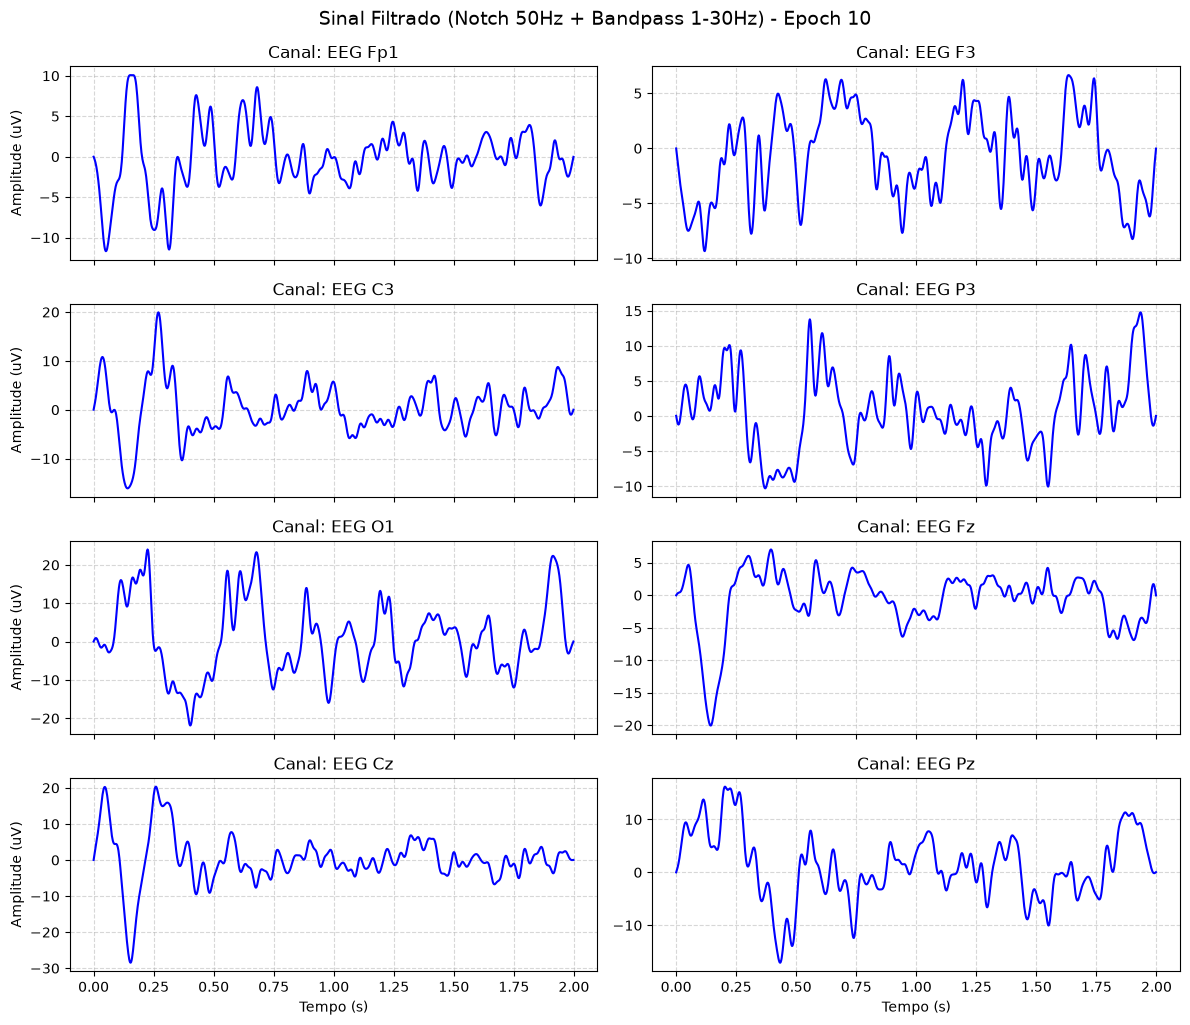

In [6]:
# Visualizando a mesma época após a filtragem
epochs_filtradas_8 = epochs_filtradas.copy().pick(picks=channels_8)
plots_evoked(epochs_filtradas_8[epo], color="blue", title=f"Sinal Filtrado (Notch 50Hz + Bandpass 1-30Hz) - Epoch {epo}")


---
### 6. Comparação Direta Sobreposta (Antes vs Depois)
Sobreposição direta do sinal bruto (vermelho) com o sinal filtrado (azul) para comprovação do efeito dos filtros em cada canal.


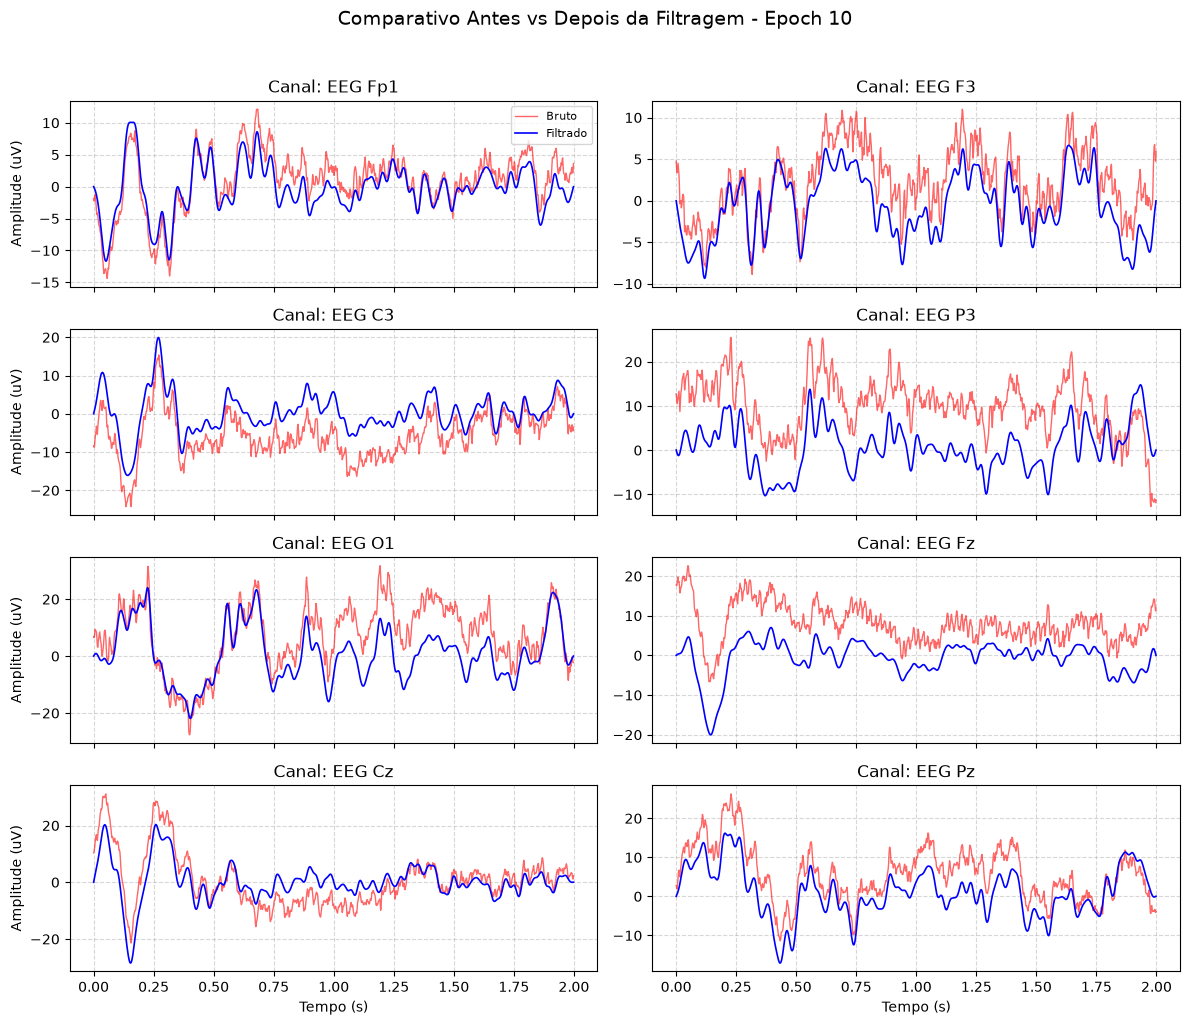

In [7]:
data_raw = epochs_8[epo].get_data()[0]
data_filt = epochs_filtradas_8[epo].get_data()[0]
times = epochs_8.times

fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(12, 10), sharex=True)
axes = axes.flatten()

for i, ch_name in enumerate(channels_8):
    ax = axes[i]
    ax.plot(times, data_raw[i], label="Bruto", color="red", alpha=0.6, linewidth=1.0)
    ax.plot(times, data_filt[i], label="Filtrado", color="blue", linewidth=1.2)
    ax.set_title(f"Canal: {ch_name}")
    ax.grid(True, linestyle="--", alpha=0.5)
    if i == 0:
        ax.legend(loc="upper right", fontsize=8)
    if i % 2 == 0:
        ax.set_ylabel("Amplitude (uV)")
    if i >= 6:
        ax.set_xlabel("Tempo (s)")

plt.suptitle(f"Comparativo Antes vs Depois da Filtragem - Epoch {epo}", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()


---
### 7. Salvando os Dados Filtrados
Persistimos os dados filtrados tanto em formato MNE (`.fif`) quanto NumPy (`.npy`) no diretório `output/` para consumo pelo notebook de gráficos (`charts.ipynb`).


In [8]:
# Salvando o objeto EpochsArray filtrado em um arquivo .fif e em .npy
fif_out = DATA_DIR / "eeg_epochs_filtered-epo.fif"
npy_out = DATA_DIR / "eeg_epochs_filtered.npy"

epochs_filtradas.save(str(fif_out), overwrite=True)
np.save(str(npy_out), epochs_filtradas.get_data())

print(f"Epochs filtradas salvas em:")
print(f" - MNE .fif: {fif_out.resolve()}")
print(f" - NumPy .npy: {npy_out.resolve()}")


Overwriting existing file.
Overwriting existing file.
Overwriting existing file.
Epochs filtradas salvas em:
 - MNE .fif: /home/andre/Documentos/Git/neural-ca/output/eeg_epochs_filtered-epo.fif
 - NumPy .npy: /home/andre/Documentos/Git/neural-ca/output/eeg_epochs_filtered.npy
